# Étape 1 — Chargement et Analyse exploratoire des données (EDA)

Objectif : comprendre la structure du dataset, vérifier sa qualité (valeurs manquantes, doublons, incohérences, outliers), produire des statistiques descriptives, étudier la cible `Mental_Health_Risk` et identifier les variables les plus liées au risque.

## 1. Chargement des données

On importe les librairies et on charge le CSV depuis `Data/`. Le chemin est construit avec `Path` pour rester fiable selon l'endroit d'où le notebook est lancé.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

DATASETPATH = Path.cwd() / "Data" / "student_mental_health.csv"

df = pd.read_csv(DATASETPATH)

df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


## 2. Structure générale du dataset

On regarde les dimensions, les types de colonnes et les infos générales (combien de lignes/colonnes, quelles sont les numériques vs catégorielles).

In [2]:
print(f"Dimensions : {df.shape[0]} lignes × {df.shape[1]} colonnes")
print()
df.info()

Dimensions : 2000 lignes × 17 colonnes

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Atten

**Séparation des colonnes par type** — listes des colonnes numériques, catégorielles et de la cible, réutilisées dans tout le notebook.

In [3]:
# Séparation des colonnes par type, utile pour la suite
NUMERIC_COLS = ["Age", "Sleep_Hours", "Study_Hours_Per_Week", "GPA", "Social_Media_Hours",
                "Screen_Time_Hours", "Financial_Stress", "Family_Support", "Attendance_Rate"]
CATEGORICAL_COLS = ["Gender", "Year_of_Study", "Physical_Activity", "Part_Time_Job",
                    "Diet_Quality", "Previous_Mental_Health_History"]
TARGET = "Mental_Health_Risk"

print(f"Numériques : {len(NUMERIC_COLS)} | Catégorielles : {len(CATEGORICAL_COLS)} | Cible : {TARGET}")

Numériques : 9 | Catégorielles : 6 | Cible : Mental_Health_Risk


## 3. Statistiques descriptives

`describe()` donne pour chaque variable numérique moyenne, écart-type, min/max et quartiles. On regarde aussi les stats des variables catégorielles (nombre de modalités, valeur la plus fréquente).

In [4]:
df.describe().round(2)

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.00,2000.00,1938.00,2000.00,1962.00,1942.00,2000.00,1909.00,1946.00,1953.00
mean,21.13,2.63,6.76,20.00,2.56,6.01,8.55,5.96,6.52,85.08
std,2.14,1.32,1.13,5.72,0.34,1.15,1.66,1.89,1.84,7.22
min,17.00,1.00,3.30,2.40,1.50,2.10,3.30,1.40,1.70,54.40
25%,20.00,1.00,6.00,16.00,2.32,5.22,7.40,4.50,5.10,80.30
50%,21.00,2.00,6.70,19.80,2.56,6.00,8.50,6.10,6.70,85.10
75%,23.00,4.00,7.60,24.00,2.79,6.70,9.70,7.40,8.00,90.00
max,29.00,5.00,10.00,38.30,3.66,10.00,14.00,10.00,9.90,100.00


**Statistiques descriptives des variables catégorielles** — nombre de modalités, valeur la plus fréquente.

In [5]:
df.describe(include="object")

/tmp/ipykernel_473986/702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Student_ID,Gender,Physical_Activity,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
count,2000,2000,2000,2000,1931,2000,2000
unique,2000,3,3,2,3,2,3
top,STU0001,Female,Moderate,No,Average,No,High
freq,1,971,906,1289,860,1408,680


## 4. Valeurs manquantes

On compte les NaN par colonne, en nombre et en pourcentage. Cela guidera le choix de la méthode d'imputation à l'étape 2.

In [6]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"manquants": missing, "pct": missing_pct}).sort_values("manquants", ascending=False)
missing_df[missing_df["manquants"] > 0]

,manquants,pct
Financial_Stress,91,4.55
Diet_Quality,69,3.45
Sleep_Hours,62,3.10
Social_Media_Hours,58,2.90
Family_Support,54,2.70
Attendance_Rate,47,2.35
GPA,38,1.90


**Visualisation des valeurs manquantes** — pourcentage de NaN par colonne concernée.

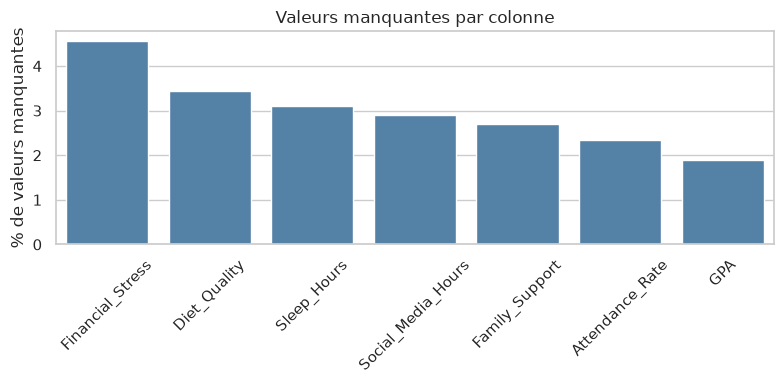

In [7]:
# Visualisation des valeurs manquantes
missing_plot = missing_df[missing_df["manquants"] > 0]
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=missing_plot.index, y=missing_plot["pct"], ax=ax, color="steelblue")
ax.set_ylabel("% de valeurs manquantes")
ax.set_xlabel("")
ax.set_title("Valeurs manquantes par colonne")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Doublons

On vérifie les doublons sur toutes les colonnes et spécifiquement sur l'identifiant `Student_ID` (deux étudiants ne peuvent pas avoir le même ID).

In [8]:
print(f"Lignes dupliquées (toutes colonnes) : {df.duplicated().sum()}")
print(f"Student_ID en double : {df['Student_ID'].duplicated().sum()}")

Lignes dupliquées (toutes colonnes) : 0
Student_ID en double : 0


## 6. Incohérences dans les variables catégorielles

On liste les valeurs uniques de chaque colonne catégorielle pour repérer des catégories mal écrites, des incohérences ou des modalités inattendues.

In [9]:
for col in CATEGORICAL_COLS + [TARGET]:
    print(f"{col} : {sorted(df[col].dropna().unique().tolist())}")

Gender : ['Female', 'Male', 'Non-binary']
Year_of_Study : [1, 2, 3, 4, 5]
Physical_Activity : ['High', 'Low', 'Moderate']
Part_Time_Job : ['No', 'Yes']
Diet_Quality : ['Average', 'Good', 'Poor']
Previous_Mental_Health_History : ['No', 'Yes']
Mental_Health_Risk : ['High', 'Low', 'Medium']


**Vérification des plages de valeurs** des variables numériques — détection de valeurs physiquement impossibles.

In [10]:
# Vérification des plages de valeurs des numériques (valeurs physiquement impossibles ?)
df[NUMERIC_COLS].agg(["min", "max"]).T

,min,max
Age,17.0,29.00
Sleep_Hours,3.3,10.00
Study_Hours_Per_Week,2.4,38.30
GPA,1.5,3.66
Social_Media_Hours,2.1,10.00
Screen_Time_Hours,3.3,14.00
Financial_Stress,1.4,10.00
Family_Support,1.7,9.90
Attendance_Rate,54.4,100.00


## 7. Valeurs aberrantes (outliers)

Boxplots de chaque variable numérique. Les outliers détectés ici seront traités à l'étape 2 (méthode IQR), on les repère seulement à ce stade.

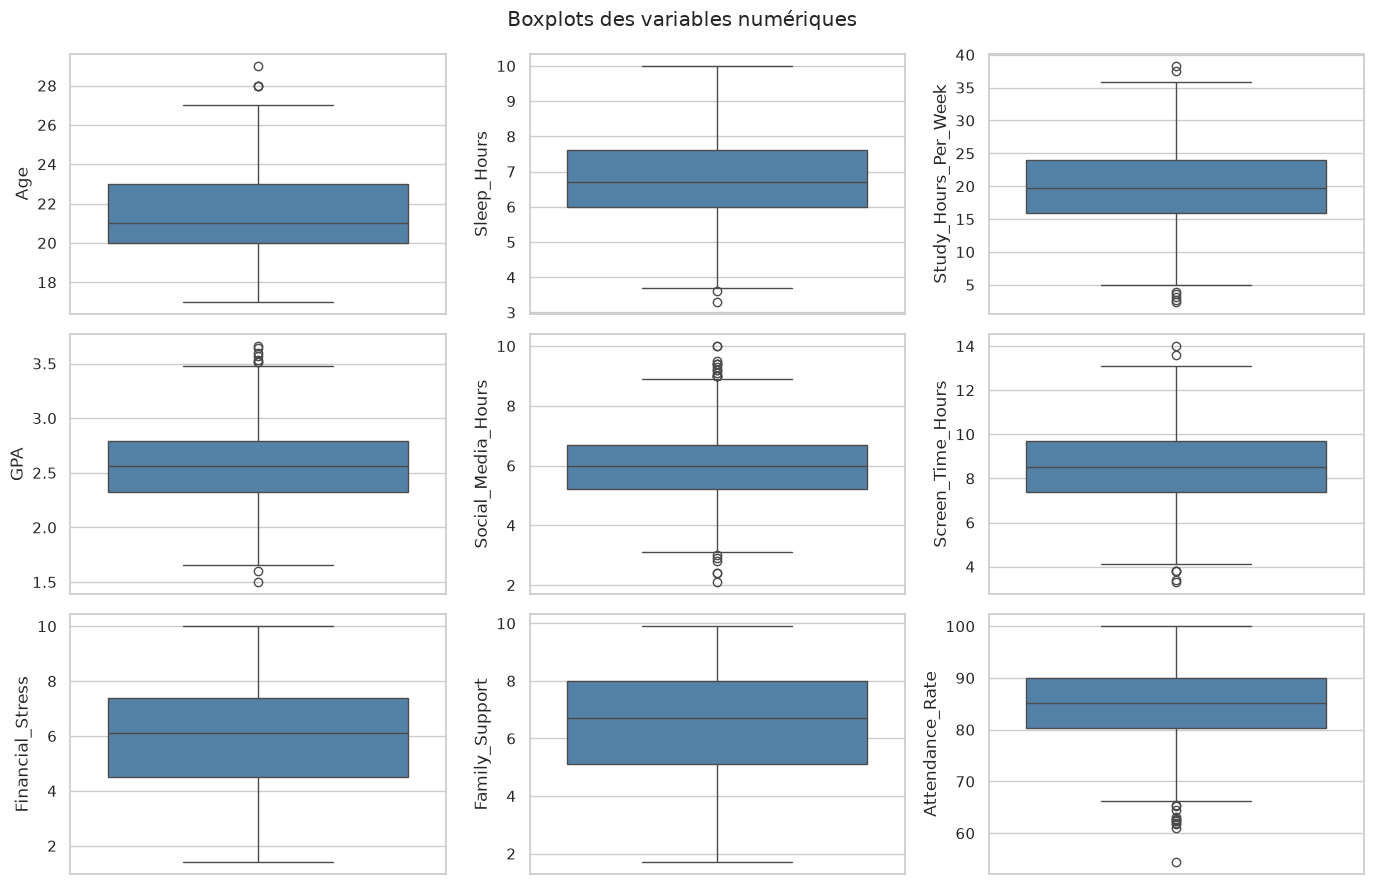

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for ax, col in zip(axes.flat, NUMERIC_COLS):
    sns.boxplot(data=df, y=col, ax=ax, color="steelblue")
    ax.set_xlabel("")
fig.suptitle("Boxplots des variables numériques")
plt.tight_layout()
plt.show()

## 8. Distribution de la cible `Mental_Health_Risk`

On regarde la répartition des 3 classes (Low / Medium / High) pour vérifier s'il y a un déséquilibre des classes.

                    nombre   pct
Mental_Health_Risk              
High                   680  34.0
Medium                 660  33.0
Low                    660  33.0


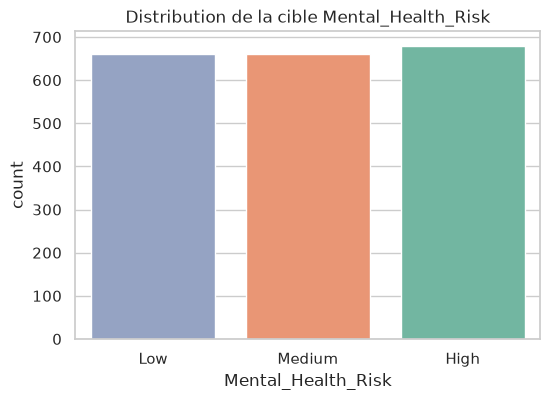

In [12]:
target_counts = df[TARGET].value_counts()
target_pct = df[TARGET].value_counts(normalize=True) * 100
print(pd.DataFrame({"nombre": target_counts, "pct": target_pct.round(1)}))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x=TARGET, order=["Low", "Medium", "High"], ax=ax, palette="Set2", hue=TARGET)
ax.set_title("Distribution de la cible Mental_Health_Risk")
plt.show()

## 9. Relations entre variables explicatives et la cible

### 9.1 Variables numériques

Boxplots de chaque variable numérique selon la classe de risque. Une variable est intéressante si sa distribution change nettement entre Low / Medium / High.

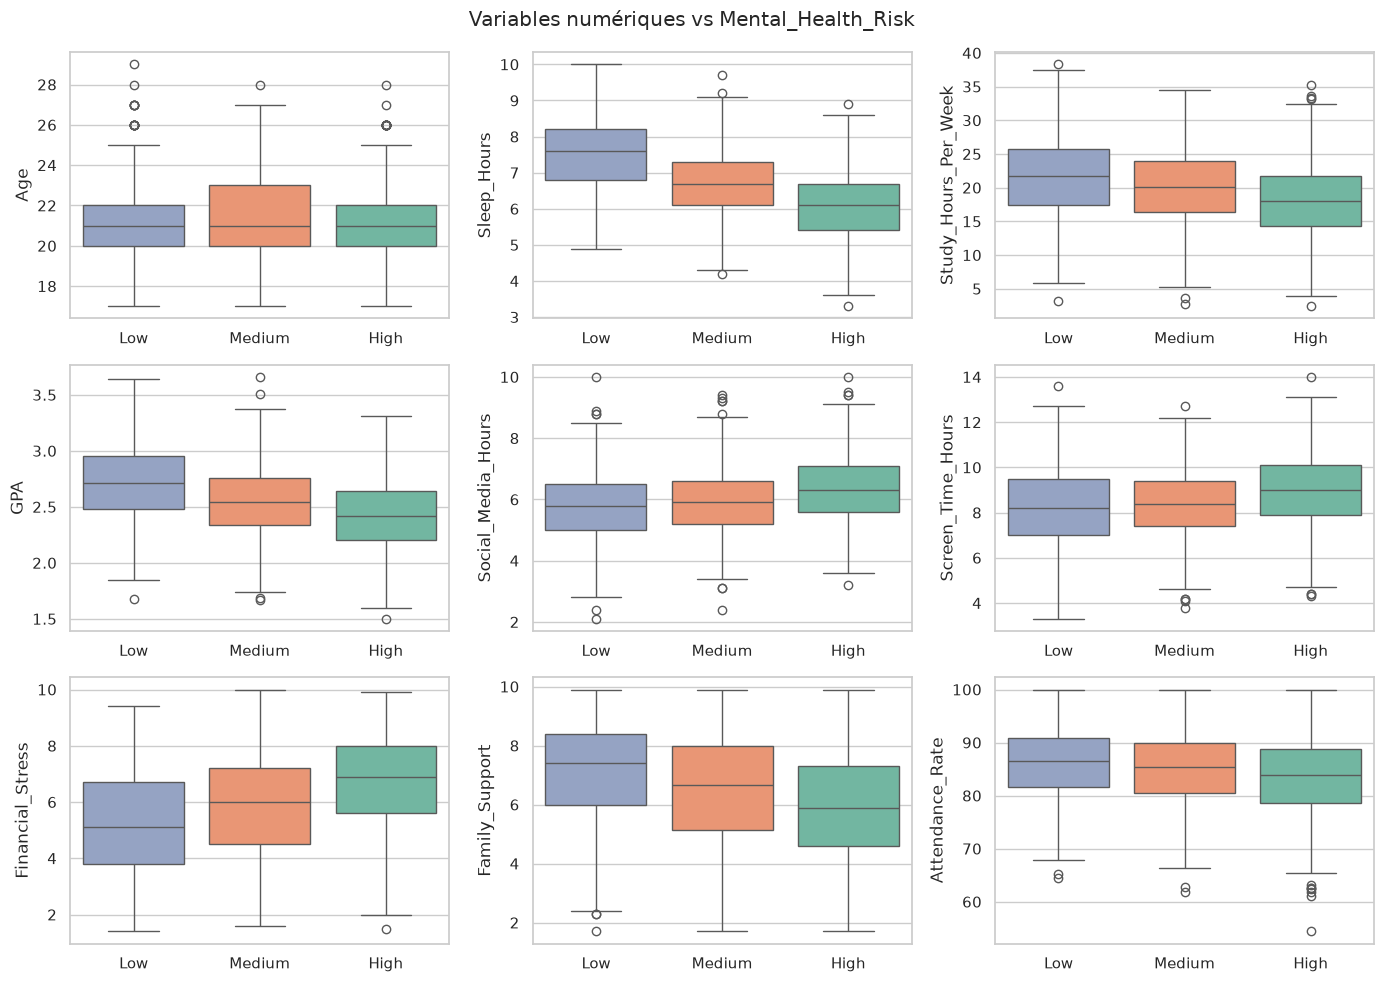

In [13]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, NUMERIC_COLS):
    sns.boxplot(data=df, x=TARGET, y=col, order=["Low", "Medium", "High"], ax=ax, hue=TARGET, palette="Set2")
    ax.set_xlabel("")
fig.suptitle("Variables numériques vs Mental_Health_Risk")
plt.tight_layout()
plt.show()

### 9.2 Variables catégorielles

Pour chaque catégorielle, on calcule la proportion de chaque niveau de risque au sein de chaque modalité. Si ces proportions changent beaucoup d'une modalité à l'autre, la variable est liée au risque.

In [14]:
for col in CATEGORICAL_COLS:
    crosstab = pd.crosstab(df[col], df[TARGET], normalize="index")
    crosstab = crosstab[["Low", "Medium", "High"]]
    print(f"--- {col} ---")
    print((crosstab * 100).round(1))
    print()


--- Gender ---
Mental_Health_Risk   Low  Medium  High
Gender                                
Female              33.5    31.9  34.6
Male                31.8    34.9  33.4
Non-binary          40.2    25.8  34.0

--- Year_of_Study ---
Mental_Health_Risk   Low  Medium  High
Year_of_Study                         
1                   25.9    28.5  45.6
2                   28.2    37.8  34.0
3                   35.7    35.7  28.6
4                   38.1    29.8  32.1
5                   47.4    32.4  20.2

--- Physical_Activity ---
Mental_Health_Risk   Low  Medium  High
Physical_Activity                     
High                49.4    30.4  20.2
Low                 22.8    31.2  45.9
Moderate            33.1    35.5  31.3

--- Part_Time_Job ---
Mental_Health_Risk   Low  Medium  High
Part_Time_Job                         
No                  36.2    33.5  30.3
Yes                 27.1    32.1  40.8

--- Diet_Quality ---
Mental_Health_Risk   Low  Medium  High
Diet_Quality                    

**Visualisation** — proportion de chaque classe de risque au sein de chaque modalité (barres empilées, %).

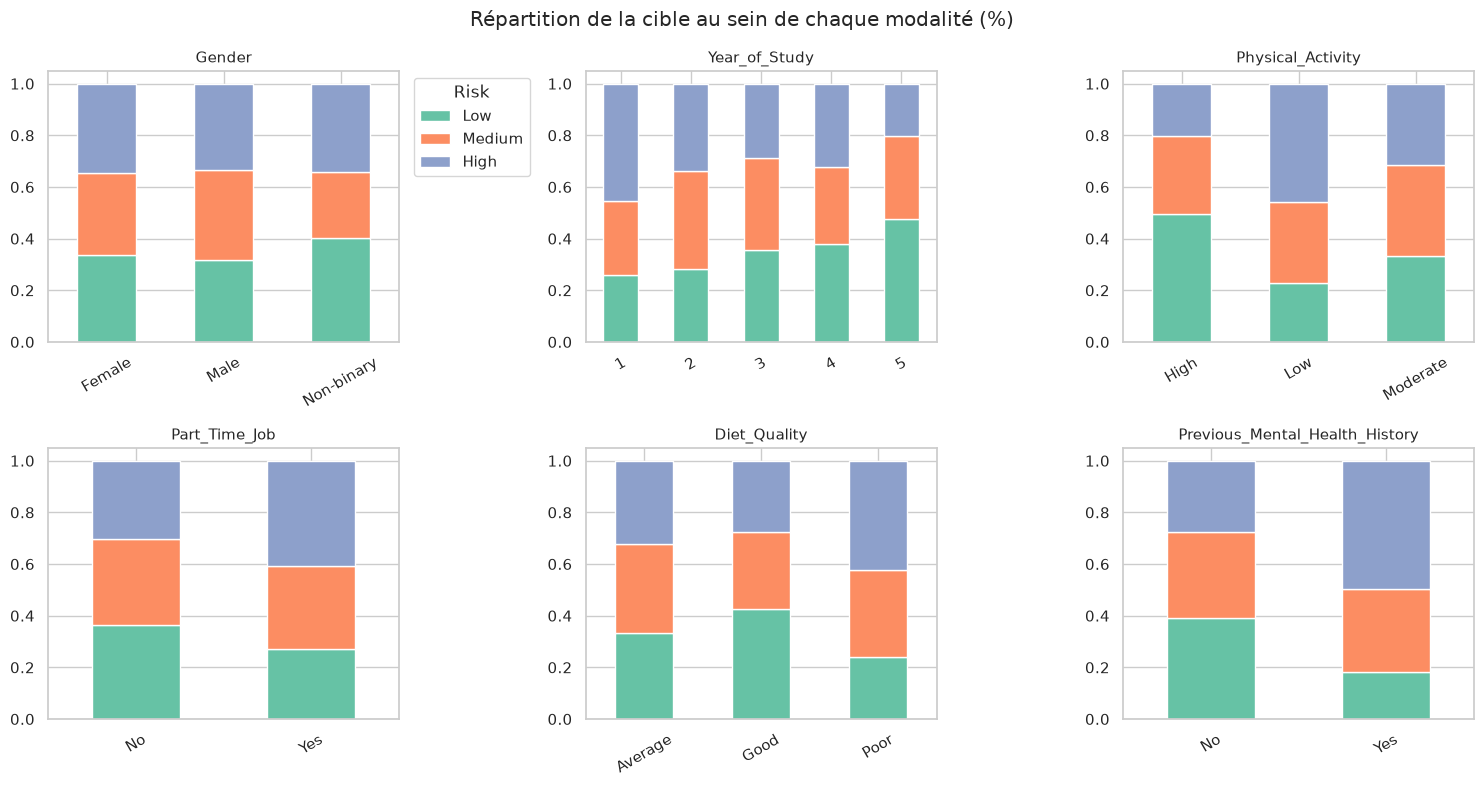

In [15]:
# Visualisation : proportion de chaque classe de risque par modalité
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, CATEGORICAL_COLS):
    crosstab = pd.crosstab(df[col], df[TARGET], normalize="index")[["Low", "Medium", "High"]]
    crosstab.plot(kind="bar", stacked=True, ax=ax, color=sns.color_palette("Set2", 3), legend=False)
    ax.set_title(col, fontsize=11)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
axes.flat[0].legend(title="Risk", bbox_to_anchor=(1.02, 1))
fig.suptitle("Répartition de la cible au sein de chaque modalité (%)")
plt.tight_layout()
plt.show()

## 10. Corrélations entre les variables

La cible étant ordinale (Low < Medium < High), on l'encode temporairement en 0/1/2 uniquement pour calculer les corrélations (Spearman, adapté aux variables ordinales). On utilise un counterplot pour l'exploration.

In [16]:
# Encodage temporaire de la cible pour l'analyse de corrélations
RISK_ENCODER = {"Low": 0, "Medium": 1, "High": 2}
corr_risk = df[NUMERIC_COLS + [TARGET]].copy()
corr_risk[TARGET] = corr_risk[TARGET].map(RISK_ENCODER)

correlations = corr_risk.corr(method="spearman")[TARGET].drop(TARGET).sort_values(ascending=False)
print("Corrélation de chaque variable numérique avec le risque :")
print(correlations.round(3))

Corrélation de chaque variable numérique avec le risque :
Financial_Stress        0.311
Social_Media_Hours      0.198
Screen_Time_Hours       0.173
Age                     0.005
Attendance_Rate        -0.142
Study_Hours_Per_Week   -0.240
Family_Support         -0.250
GPA                    -0.344
Sleep_Hours            -0.541
Name: Mental_Health_Risk, dtype: float64


**Heatmap complète des corrélations** entre variables numériques (Spearman) + visuel du classement vis-à-vis du risque.

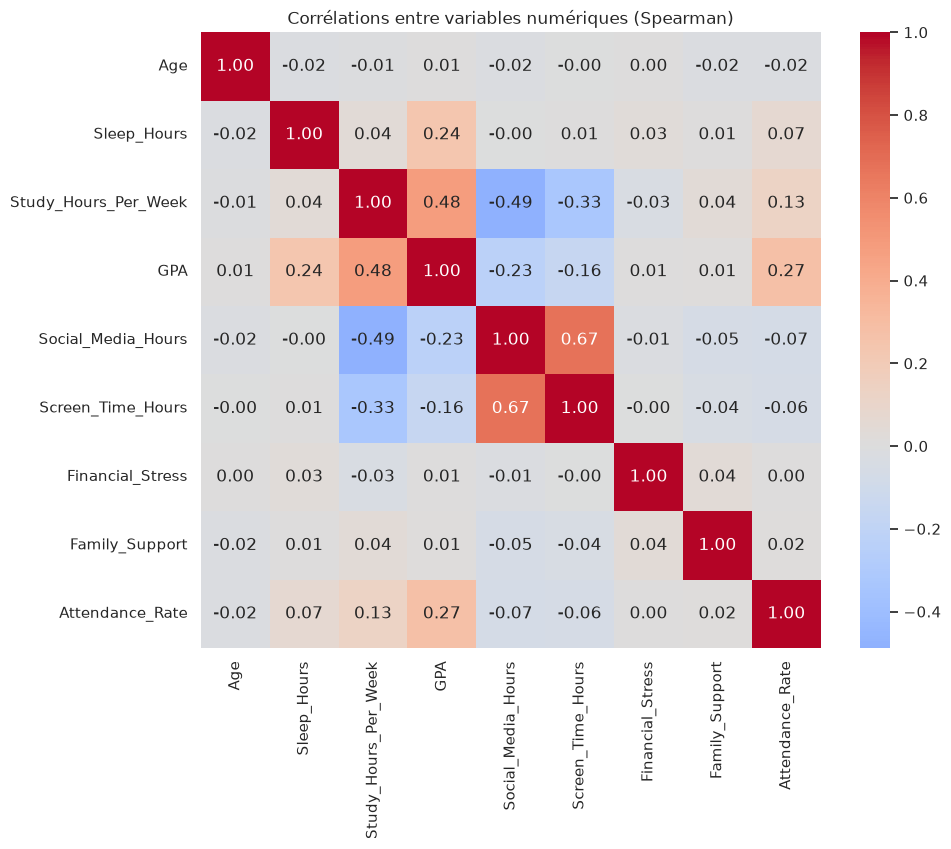

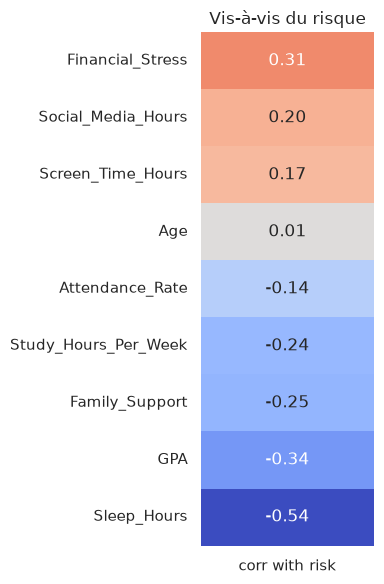

In [17]:
# Lien cible <-> features les plus corrélées + heatmap complète
plt.figure(figsize=(10, 8))
corr_matrix = df[NUMERIC_COLS].corr(method="spearman")
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélations entre variables numériques (Spearman)")
plt.show()

plt.figure(figsize=(4, 6))
sns.heatmap(correlations.to_frame("corr with risk"), annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar=False)
plt.title("Vis-à-vis du risque")
plt.tight_layout()
plt.show()

## 11. Synthèse

À compléter après exécution : récapitulatif des variables les plus liées au risque, et décisions à prendre pour l'étape 2.

- **Qualité** : 0 doublon, ~2–4% de NaN sur 7 colonnes → imputation à prévoir (étape 2).
- **Cible** : 3 classes équilibrées (~33% chacune) → pas besoin de SMOTE.
- **Outliers** : à vérifier sur les boxplots, traitement IQR prévu à l'étape 2.
- **Variables les plus liées au risque** : voir le classement des corrélations ci-dessus.
- `Student_ID` = simple identifiant → à exclure du modèle.